In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from statsmodels.nonparametric.smoothers_lowess import lowess

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    pass
else:
    plt.style.use("science")

from tasks.policies import load_policy_results


In [2]:
plt.rcParams["font.size"] = 16

In [3]:
def values_match(values, target):
    values = pd.Series(values)
    try:
        matches = np.isclose(values.to_numpy(dtype=float), float(target))
    except (TypeError, ValueError):
        matches = values == target
    return pd.Series(matches, index=values.index)


def format_value_label(value):
    if isinstance(value, (float, np.floating)):
        return f"{value:g}"
    return str(value)


PRETTY_LABELS = {
    "best_response_proportion": "best-response proportion",
    "centered_mean_welfare.mean": "centered mean welfare",
    "n_agents": "agents",
    "random.p_act": "random action probability",
}


def pretty_label(name):
    fallback = name.replace("_", " " ).replace(".", " " )
    return PRETTY_LABELS.get(name, fallback)


def build_welfare_delta_frame(ds, stat, baseline_proportion=1.0):
    value = (
        ds["x"]
        .sel(observable=stat)
        .isel(step=-1, drop=True)
        .reset_coords(drop=True)
        .rename("value")
    )
    required_dims = {"n_agents", "best_response_proportion", "parameter_row"}
    missing_dims = required_dims.difference(value.dims)
    if missing_dims:
        missing = ", ".join(sorted(missing_dims))
        raise ValueError(f"Welfare values are missing required dimensions: {missing}")

    try:
        baseline_value = value.sel(
            best_response_proportion=baseline_proportion,
            drop=True,
        ).reset_coords(drop=True).rename("baseline_value")
    except KeyError as exc:
        raise ValueError(
            f"No best_response_proportion={baseline_proportion} baseline is available."
        ) from exc

    p_act = (
        ds["theta"]
        .sel(theta_parameter="random.p_act", drop=True)
        .reset_coords(drop=True)
        .rename("random.p_act")
    )
    p_act, value = xr.align(p_act, value, join="exact")
    delta = (value - baseline_value).rename("delta")

    frame = (
        xr.Dataset({
            "value": value,
            "baseline_value": baseline_value,
            "delta": delta,
            "random.p_act": p_act,
        })
        .to_dataframe()
        .reset_index()
    )
    columns = [
        "n_agents",
        "parameter_row",
        "best_response_proportion",
        "random.p_act",
        "value",
        "baseline_value",
        "delta",
    ]
    return (
        frame[columns]
        .dropna(subset=columns)
        .sort_values(["n_agents", "best_response_proportion", "parameter_row"])
        .reset_index(drop=True)
    )


def panel_grid(panel_count, *, ncols=3, sharex=False, sharey=False, panel_size=(6, 6)):
    nrows = (panel_count + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
        sharex=sharex,
        sharey=sharey,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[panel_count:]:
        ax.set_visible(False)
    return fig, axes


def smooth_lowess_series(
    series,
    x_dim,
    *,
    y_dim="delta",
    lowess_frac=0.2,
    smooth_points=200,
):
    series = series.sort_values(x_dim)
    x = series[x_dim].to_numpy(dtype=float)
    y = series[y_dim].to_numpy(dtype=float)

    if len(series) < 3 or np.unique(x).size < 2:
        return pd.DataFrame({
            x_dim: x,
            "center": y,
            "lower": y,
            "upper": y,
        })

    x_grid = np.linspace(x.min(), x.max(), smooth_points)
    center = lowess(
        y,
        x,
        frac=lowess_frac,
        xvals=x_grid,
        is_sorted=True,
        return_sorted=False,
    )
    fitted = lowess(
        y,
        x,
        frac=lowess_frac,
        xvals=x,
        is_sorted=True,
        return_sorted=False,
    )
    residual_variance = lowess(
        (y - fitted) ** 2,
        x,
        frac=lowess_frac,
        xvals=x_grid,
        is_sorted=True,
        return_sorted=False,
    )
    spread = np.sqrt(np.maximum(residual_variance, 0.0))

    return pd.DataFrame({
        x_dim: x_grid,
        "center": center,
        "lower": center - spread,
        "upper": center + spread,
    })


def plot_lowess_delta_panels(
    delta_frame,
    stat,
    *,
    panel_dim="n_agents",
    hue_dim="best_response_proportion",
    x_dim="random.p_act",
    y_dim="delta",
    baseline_proportion=1.0,
    include_baseline=False,
    lowess_frac=0.2,
    smooth_points=200,
    ncols=3,
    xlim=(0, 1),
    metric_label=None,
):
    required_columns = {panel_dim, hue_dim, x_dim, y_dim}
    missing_columns = required_columns.difference(delta_frame.columns)
    if missing_columns:
        missing = ", ".join(sorted(missing_columns))
        raise ValueError(f"Delta frame is missing required columns: {missing}")

    line_data = delta_frame.dropna(subset=[panel_dim, hue_dim, x_dim, y_dim]).copy()
    if not include_baseline:
        baseline_mask = values_match(line_data[hue_dim], baseline_proportion)
        line_data = line_data.loc[~baseline_mask].copy()
    if line_data.empty:
        raise ValueError("No rows remain for the LOWESS delta plot.")

    hue_values = np.sort(line_data[hue_dim].dropna().unique())
    panel_values = np.sort(line_data[panel_dim].dropna().unique())
    palette = dict(zip(hue_values, sns.color_palette("viridis", len(hue_values))))
    fig, axes = panel_grid(len(panel_values), ncols=ncols, sharex=True, sharey=True)
    baseline_label = format_value_label(baseline_proportion)
    metric_label = pretty_label(stat) if metric_label is None else metric_label
    if hue_dim == "best_response_proportion" and np.isclose(float(baseline_proportion), 1.0):
        baseline_description = "full best-response baseline"
    else:
        baseline_description = f"{pretty_label(hue_dim)}={baseline_label}"
    fig.suptitle(f"Final-step {metric_label}: change from {baseline_description}", y=1.03)
    y_label = f"{metric_label} change (asinh scale)"

    for index, (ax, panel_value) in enumerate(zip(axes, panel_values)):
        ax.set_title(f"{pretty_label(panel_dim)} = {format_value_label(panel_value)}")
        panel = line_data[line_data[panel_dim] == panel_value]

        for hue_value, series in panel.groupby(hue_dim, sort=True):
            smooth = smooth_lowess_series(
                series,
                x_dim,
                y_dim=y_dim,
                lowess_frac=lowess_frac,
                smooth_points=smooth_points,
            )
            x = smooth[x_dim].to_numpy(dtype=float)
            center = smooth["center"].to_numpy(dtype=float)
            lower = smooth["lower"].to_numpy(dtype=float)
            upper = smooth["upper"].to_numpy(dtype=float)
            color = palette[hue_value]
            label = format_value_label(hue_value)

            ax.plot(x, center, color=color, linewidth=2, label=label)
            ax.fill_between(x, lower, upper, color=color, alpha=0.18, linewidth=0)

        ax.set_yscale("asinh", linear_width=0.5)
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.35)
        ax.set_xlabel(pretty_label(x_dim))
        if index == 0:
            ax.set_ylabel(y_label, labelpad=12)
        ax.grid(alpha=0.25)
        if xlim is not None:
            ax.set_xlim(*xlim)

    handles, labels = [], []
    for ax in axes[:len(panel_values)]:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            break
    if handles:
        fig.legend(handles, labels, title=pretty_label(hue_dim), loc="center left", bbox_to_anchor=(1.01, 0.5))

    plt.show()
    return line_data, fig, axes


In [4]:
result_store = "artifacts/simulation_runs/run-20260525T165846.zarr"

In [5]:
result_store_path = Path(result_store).expanduser()
if not result_store_path.is_absolute():
    result_store_path = project_root / result_store_path

stat = "centered_mean_welfare.mean"
ds = load_policy_results(result_store_path, stats=[stat])

print(f"Loaded: {result_store_path.relative_to(project_root)}")
print("Stats:", list(ds.coords["observable"].values))
print("xarray dimensions:", list(ds["x"].dims))
print("theta parameters:", list(ds.coords["theta_parameter"].values))


Loaded: artifacts/simulation_runs/run-20260525T165846.zarr
Stats: [np.str_('centered_mean_welfare.mean')]
xarray dimensions: ['n_agents', 'best_response_proportion', 'parameter_row', 'step', 'observable']
theta parameters: [np.str_('n_agents'), np.str_('benefit_to_cost_ratio'), np.str_('distance_discount'), np.str_('visibility_distance'), np.str_('best_response.outside_optimism'), np.str_('best_response.exploration'), np.str_('random.p_act')]


In [6]:
baseline_proportion = 1.0
x_dim = "random.p_act"


In [7]:
delta_frame = build_welfare_delta_frame(
    ds,
    stat,
    baseline_proportion=baseline_proportion,
)
delta_frame.head()


,n_agents,parameter_row,best_response_proportion,random.p_act,value,baseline_value,delta
0,10,0,0.0,0.885681,-0.168502,0.788429,-0.956932
1,10,1,0.0,0.156769,-0.156847,0.644677,-0.801525
2,10,2,0.0,0.638592,0.450936,0.106867,0.344070
3,10,3,0.0,0.413586,-0.182172,1.000000,-1.182172
4,10,4,0.0,0.004215,0.483084,0.841676,-0.358592


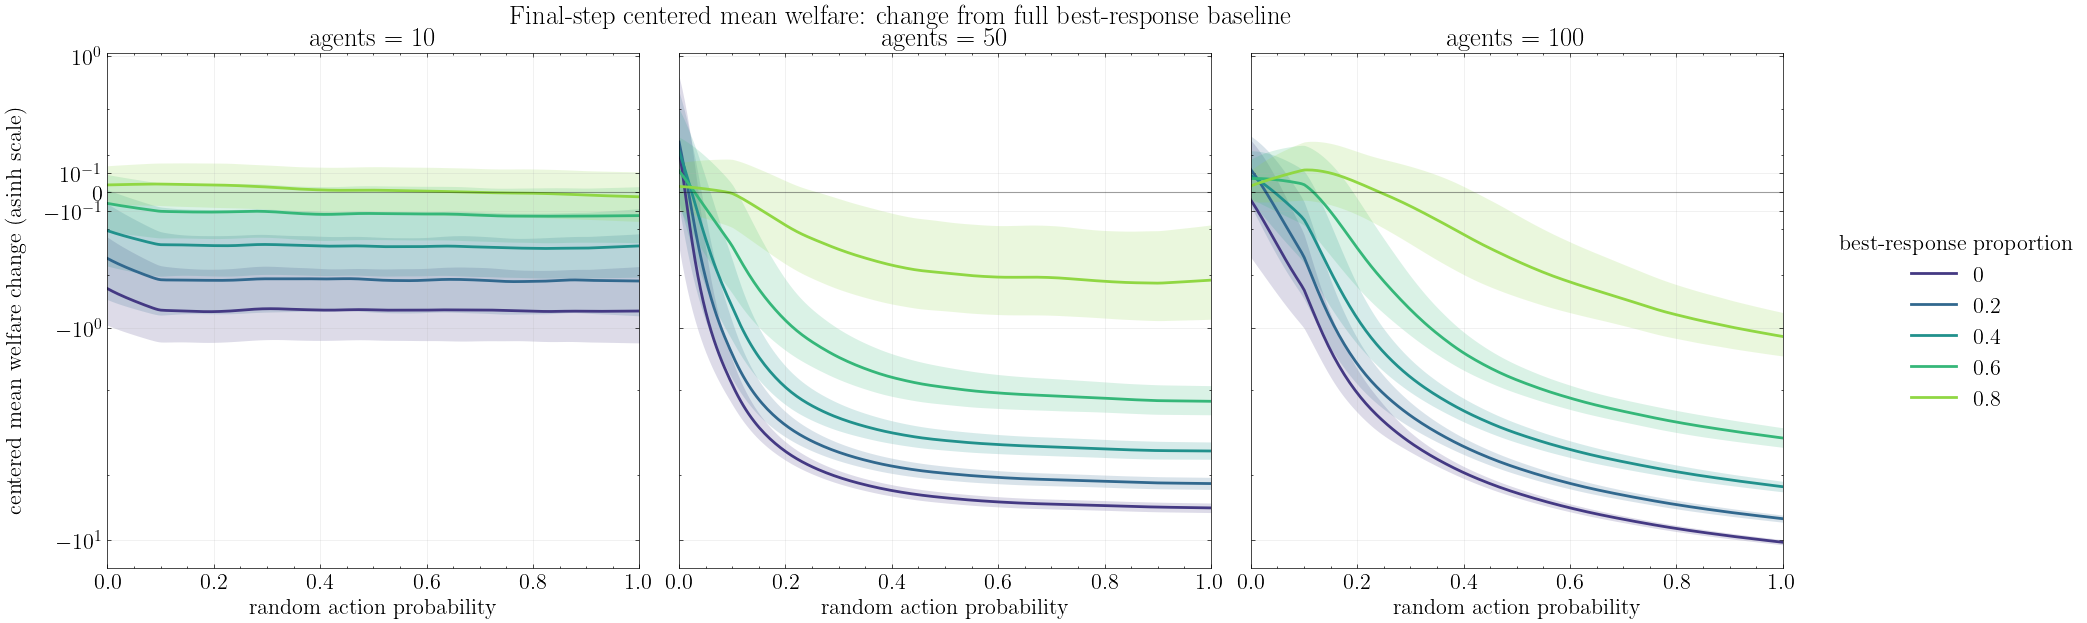

In [8]:
line_data, fig, axes = plot_lowess_delta_panels(
    delta_frame,
    stat,
    x_dim=x_dim,
    baseline_proportion=baseline_proportion,
)